# Week 03: Sri Lankan House Price Regression — Live Data

End-to-end regression on ~1,300 house listings scraped from LankaPropertyWeb (Colombo + suburbs).

**Flow:** load → clean → EDA → split → baseline → linear models → cross-validation → diagnostics → test → predict

## 1. Setup

In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

pd.set_option("display.width", 140)
RANDOM_STATE = 42

## 2. Load the Scraped Data

`scrape_lankapropertyweb.py` collects listing ids from the search pages, then reads each listing's detail page. Re-run it to refresh the data (~25 min, polite 1 s delay).

In [2]:
DATA = "sl_houses_live.csv"
if not os.path.exists(DATA):
    DATA = "https://raw.githubusercontent.com/AdhiDevX369/ml-begginer/main/week3/sl_houses_live.csv"
# !python scrape_lankapropertyweb.py 1300   # uncomment to scrape fresh data

raw = pd.read_csv(DATA, dtype={"listing_id": str})
print(raw.shape)
raw.head()

(1316, 11)


,listing_id,card_location,title,locality,property_type,raw_beds,raw_baths,raw_sqft,raw_perches,raw_price,scraped_on
0,5967329,Colombo 3,￭ Colombo 03 ￭ 06BR House For Sale ￭ (NK11984),Colombo 3,House,6.0,5.0,6000 sq.ft.,36 perches,NaN,2026-10-27
1,5969455,Colombo 7,"4 Bedroom House for Sale in Rosmead Place, Col...",Colombo 7,House,4.0,3.0,3580 sq.ft.,12.8 perches,"Rs. 371,500,000",2026-10-27
2,5910474,Colombo 6,Luxury Three storey 5 Bedroom House for Sale i...,Colombo 6,House,5.0,4.0,4400 sq.ft.,12 perches,"Rs. 180,000,000 ($ 543,900)",2026-10-27
3,5968672,Colombo 15,🏡 House for Sale at Land Value – 16 Perches,Colombo 15,House,2.0,1.0,4356 sq.ft.,16 perches,"Rs. 51,200,000",2026-10-27
4,5825030,Colombo 7,House for sale in Colombo 7 - Rs. 700 Mn ONO,Colombo 7,House,5.0,5.0,8000 sq.ft.,17.25 perches,"Rs. 700,000,000",2026-10-27


In [3]:
raw.isna().sum()

listing_id         0
card_location      0
title              3
locality           3
property_type      3
raw_beds           8
raw_baths         45
raw_sqft          83
raw_perches      101
raw_price         77
scraped_on         0
dtype: int64

## 3. Clean

### 3.1 Parse text to numbers

In [4]:
def first_number(s):
    return pd.to_numeric(s.astype("string").str.replace(",", "", regex=False)
                          .str.extract(r"(\d+\.?\d*)")[0], errors="coerce")

df = raw.drop_duplicates("listing_id").copy()
df["price_m"]  = first_number(df["raw_price"]) / 1e6   # "Rs. 146,000,000 ($ 485,000)" -> 146.0
df["sqft"]     = first_number(df["raw_sqft"])
df["perches"]  = first_number(df["raw_perches"])
df["bedrooms"] = first_number(df["raw_beds"])
df["bathrooms"] = first_number(df["raw_baths"])
df["location"] = df["locality"].fillna(df["card_location"]).str.strip().str.title()

df[["raw_price", "price_m", "raw_sqft", "sqft", "raw_perches", "perches"]].sample(5, random_state=1)

,raw_price,price_m,raw_sqft,sqft,raw_perches,perches
953,"Rs. 244,000,000",244.0,NaN,<NA>,NaN,<NA>
1057,"Rs. 125,000,000 ($ 380,364)",125.0,3500 sq.ft.,3500.0,7.4 perches,7.4
946,"Rs. 95,000,000",95.0,3000 sq.ft.,3000.0,8 perches,8.0
1108,"Rs. 235,000,000",235.0,8200 sq.ft.,8200.0,30 perches,30.0
223,"Rs. 320,000,000",320.0,NaN,<NA>,NaN,<NA>


### 3.2 Drop unusable rows

In [5]:
steps = [("scraped", len(df))]

df = df[df["property_type"].eq("House")]
steps.append(("houses only", len(df)))

df = df.dropna(subset=["price_m"])
steps.append(("has price (not 'on request')", len(df)))

df = df.dropna(subset=["sqft", "perches", "bedrooms"])
steps.append(("has sqft, perches, bedrooms", len(df)))

pd.DataFrame(steps, columns=["step", "rows"])

,step,rows
0,scraped,1316
1,houses only,1313
2,has price (not 'on request'),1239
3,"has sqft, perches, bedrooms",1105


### 3.3 Sanity checks

Typos are common in listings (price entered in thousands, land in sq ft, etc.). Remove physically implausible rows.

In [6]:
df["price_per_perch_m"] = df["price_m"] / df["perches"]
df["sqft_per_perch"] = df["sqft"] / df["perches"]
df[["price_m", "sqft", "perches", "bedrooms", "bathrooms", "price_per_perch_m", "sqft_per_perch"]].describe().round(1)

,price_m,sqft,perches,bedrooms,bathrooms,price_per_perch_m,sqft_per_perch
count,1105.0,1105.0,1105.0,1105.0,1079.0,1105.0,1105.0
mean,198.6,3973.1,147.4,4.8,4.0,13.1,297.3
std,199.8,2093.9,4326.1,1.6,1.6,8.7,156.8
min,8.0,22.0,1.7,1.0,1.0,0.0,0.0
25%,85.0,2600.0,9.0,4.0,3.0,6.8,194.4
50%,145.0,3500.0,13.0,4.0,4.0,10.5,272.4
75%,255.0,4900.0,19.0,6.0,5.0,17.5,361.1
max,3000.0,19974.0,143811.0,19.0,10.0,57.1,2000.0


In [7]:
rules = {
    "price 5M–3,000M":        df["price_m"].between(5, 3000),
    "sqft 400–20,000":        df["sqft"].between(400, 20000),
    "perches 2–200":          df["perches"].between(2, 200),
    "bedrooms 1–12":          df["bedrooms"].between(1, 12),
    "floor ≤ 1,000 sqft/perch": df["sqft_per_perch"] <= 1000,   # ~4 storeys on full plot
}
for name, ok in rules.items():
    print(f"{name:<26} removes {(~ok).sum():>3}")

keep = np.logical_and.reduce(list(rules.values()))
df = df[keep]

lo, hi = df["price_per_perch_m"].quantile([0.01, 0.99])
df = df[df["price_per_perch_m"].between(lo, hi)].reset_index(drop=True)
print(f"\nclean rows: {len(df)}")

price 5M–3,000M            removes   0
sqft 400–20,000            removes   6
perches 2–200              removes   5
bedrooms 1–12              removes   3
floor ≤ 1,000 sqft/perch   removes   3

clean rows: 1071


### 3.4 Group rare locations

In [8]:
counts = df["location"].value_counts()
df["area"] = df["location"].where(df["location"].map(counts) >= 10, "Other")
df["area"].value_counts()

area
Nugegoda         229
Colombo 5        164
Dehiwala         103
Colombo 7         92
Battaramulla      92
Mount Lavinia     73
Other             71
Colombo 3         58
Colombo 6         56
Kohuwala          32
Colombo 8         30
Colombo 4         27
Pelawatte         21
Kalubowila        12
Pepiliyana        11
Name: count, dtype: int64

## 4. EDA

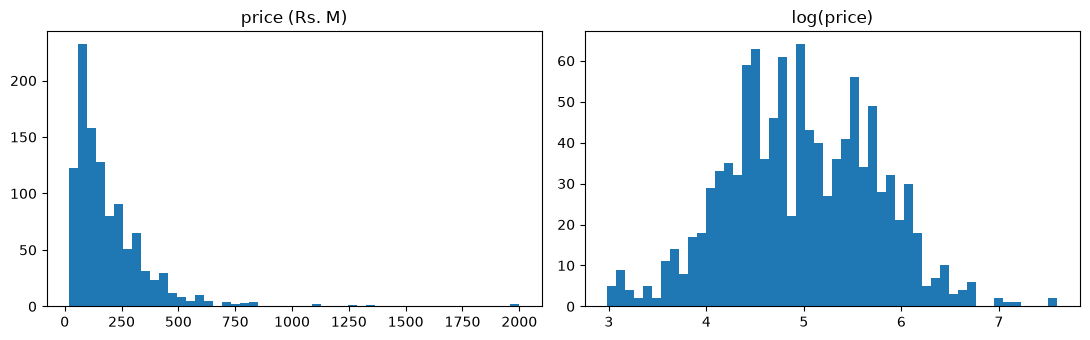

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(df["price_m"], bins=50); axes[0].set_title("price (Rs. M)")
axes[1].hist(np.log(df["price_m"]), bins=50); axes[1].set_title("log(price)")
plt.tight_layout(); plt.show()

Price is right-skewed; its log is close to normal. We will model **log(price)**.

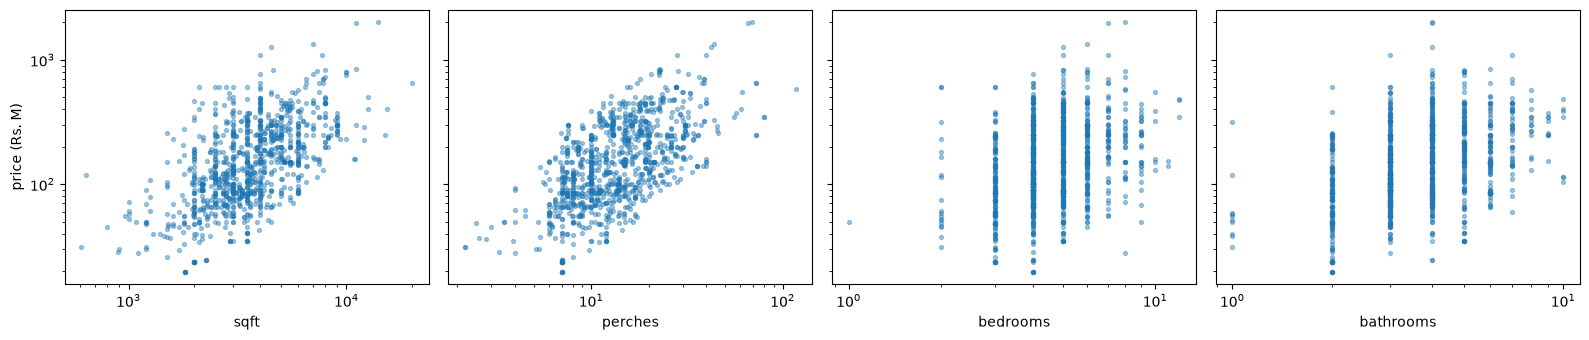

In [10]:
NUM = ["sqft", "perches", "bedrooms", "bathrooms"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, col in zip(axes, NUM):
    ax.scatter(df[col], df["price_m"], s=8, alpha=0.4)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(col)
axes[0].set_ylabel("price (Rs. M)")
plt.tight_layout(); plt.show()

In [11]:
logged = df[NUM].assign(log_price=np.log(df["price_m"]))
logged[["sqft", "perches"]] = np.log(logged[["sqft", "perches"]])
logged.corr().round(2)

,sqft,perches,bedrooms,bathrooms,log_price
sqft,1.00,0.53,0.51,0.60,0.59
perches,0.53,1.00,0.28,0.22,0.62
bedrooms,0.51,0.28,1.00,0.73,0.31
bathrooms,0.60,0.22,0.73,1.00,0.39
log_price,0.59,0.62,0.31,0.39,1.00


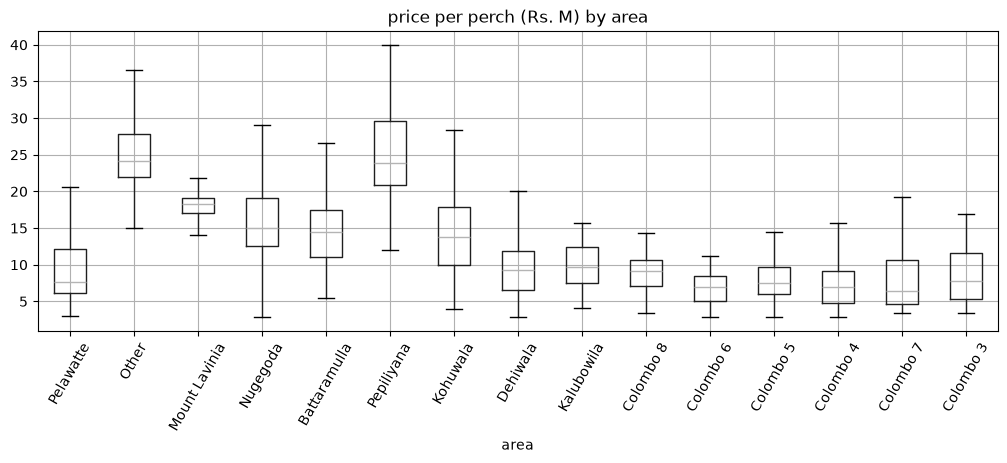

In [12]:
order = df.groupby("area")["price_per_perch_m"].median().sort_values()
df.boxplot(column="price_per_perch_m", by="area", positions=range(len(order)), rot=60, figsize=(12, 4),
           showfliers=False)
plt.xticks(range(len(order)), order.index)
plt.suptitle(""); plt.title("price per perch (Rs. M) by area"); plt.show()

Location matters as much as size: the same perch costs several times more in Colombo 7 than in the suburbs.

## 5. Train / Test Split

In [13]:
FEATURES = NUM + ["area"]
X = df[FEATURES]
y = df["price_m"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("train", X_train.shape, " test", X_test.shape)

train (856, 5)  test (215, 5)


## 6. Models

Every model is a `Pipeline`, so imputing, scaling and encoding are learned on the training folds only (no leakage).

| # | Model | Features | Target |
|---|---|---|---|
| 0 | Baseline (median) | — | price |
| 1 | Simple LR | sqft | price |
| 2 | Multiple LR | 4 numeric | price |
| 3 | Log-log LR | 4 numeric (log sqft, log perches) | log price |
| 4 | Log-log LR + location | + one-hot area | log price |
| 5 | Ridge | same as 4 | log price |

In [14]:
log = FunctionTransformer(np.log, feature_names_out="one-to-one")

def numeric(log_size):
    size = [("log", log)] if log_size else []
    return [
        ("size", Pipeline(size + [("scale", StandardScaler())]), ["sqft", "perches"]),
        ("rooms", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
         ["bedrooms", "bathrooms"]),
    ]

def model(columns, regressor, log_target):
    pipe = Pipeline([("prep", ColumnTransformer(columns)), ("reg", regressor)])
    return TransformedTargetRegressor(pipe, func=np.log, inverse_func=np.exp) if log_target else pipe

area = [("area", OneHotEncoder(handle_unknown="ignore", drop="first"), ["area"])]

models = {
    "0 Baseline (median)":   DummyRegressor(strategy="median"),
    "1 Simple LR (sqft)":    model([("sqft", "passthrough", ["sqft"])], LinearRegression(), False),
    "2 Multiple LR":         model(numeric(False), LinearRegression(), False),
    "3 Log-log LR":          model(numeric(True), LinearRegression(), True),
    "4 Log-log LR + area":   model(numeric(True) + area, LinearRegression(), True),
    "5 Ridge + area":        model(numeric(True) + area, RidgeCV(alphas=np.logspace(-3, 3, 25)), True),
}

## 7. Cross-Validation (train set only)

In [15]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"MAE": "neg_mean_absolute_error", "MAPE": "neg_mean_absolute_percentage_error", "R2": "r2"}

rows = []
for name, m in models.items():
    cv = cross_validate(m, X_train, y_train, cv=kf, scoring=scoring)
    rows.append({"model": name,
                 "MAE (Rs. M)": -cv["test_MAE"].mean(),
                 "MAPE %": -cv["test_MAPE"].mean() * 100,
                 "R2": cv["test_R2"].mean(),
                 "R2 std": cv["test_R2"].std()})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,MAE (Rs. M),MAPE %,R2,R2 std
model,,,,
0 Baseline (median),108.630,74.825,-0.082,0.042
1 Simple LR (sqft),95.413,69.550,0.248,0.045
2 Multiple LR,90.807,60.902,0.337,0.040
3 Log-log LR,87.414,48.781,0.295,0.074
4 Log-log LR + area,48.103,28.424,0.776,0.053
5 Ridge + area,48.082,28.456,0.775,0.052


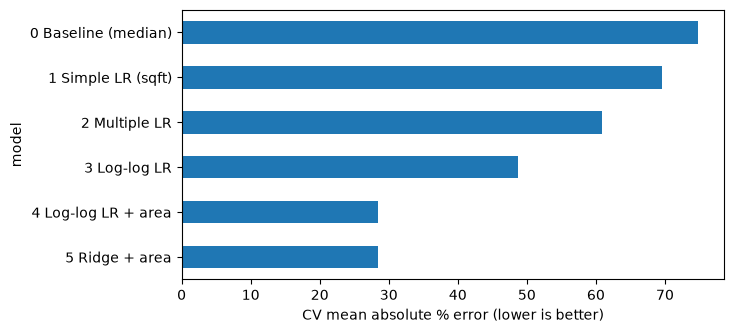

In [16]:
ax = cv_table["MAPE %"].plot.barh(figsize=(7, 3.5))
ax.invert_yaxis(); ax.set_xlabel("CV mean absolute % error (lower is better)")
plt.show()

- Log target + log size cut the % error (61% → 49%), even though $R^2$ in rupees dips: $R^2$ is dominated by the few Rs. 1,000M+ mansions, MAPE treats every house equally.
- Adding **area** is the biggest single gain.
- Ridge ≈ OLS here: with ~1,000 rows and few features, regularisation has little to fix.

## 8. Fit the Chosen Model

In [17]:
best = models["4 Log-log LR + area"].fit(X_train, y_train)

pipe = best.regressor_
names = pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(pipe.named_steps["reg"].coef_, index=names).sort_values()
coefs.round(3)

area__area_Other           -0.242
area__area_Mount Lavinia   -0.216
area__area_Pepiliyana      -0.102
area__area_Pelawatte       -0.097
area__area_Nugegoda        -0.097
rooms__bedrooms            -0.045
area__area_Kohuwala         0.012
area__area_Kalubowila       0.039
area__area_Dehiwala         0.041
rooms__bathrooms            0.096
size__sqft                  0.189
size__perches               0.330
area__area_Colombo 8        0.409
area__area_Colombo 6        0.527
area__area_Colombo 5        0.553
area__area_Colombo 4        0.732
area__area_Colombo 3        0.957
area__area_Colombo 7        1.058
dtype: float64

Reading the coefficients (log target, scaled inputs):

- `size__sqft`, `size__perches`: effect of a **1-std change in log size** on log price.
- `rooms__bedrooms` is slightly negative: for the *same* floor area, more bedrooms means smaller rooms. Bedrooms and bathrooms are correlated (0.73), so read them together.
- `area__X`: price relative to the dropped reference area, holding size fixed. $e^{\beta}-1$ is the % premium:

In [18]:
area_premium = (np.exp(coefs.filter(like="area__")) - 1).mul(100).round(0).sort_values()
ref = sorted(df["area"].unique())[0]
print(f"% price premium vs {ref}, same size house:")
area_premium.rename(lambda s: s.replace("area__area_", ""))

% price premium vs Battaramulla, same size house:


Other            -22.0
Mount Lavinia    -19.0
Pepiliyana       -10.0
Pelawatte         -9.0
Nugegoda          -9.0
Kohuwala           1.0
Kalubowila         4.0
Dehiwala           4.0
Colombo 8         51.0
Colombo 6         69.0
Colombo 5         74.0
Colombo 4        108.0
Colombo 3        160.0
Colombo 7        188.0
dtype: float64

## 9. Diagnostics (train set)

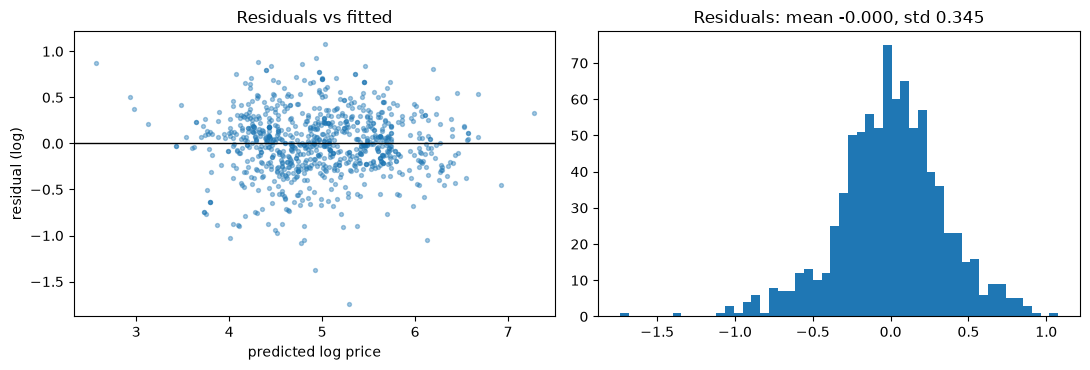

In [19]:
pred_tr = best.predict(X_train)
resid = np.log(y_train) - np.log(pred_tr)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(np.log(pred_tr), resid, s=8, alpha=0.4)
axes[0].axhline(0, color="k", lw=1)
axes[0].set_xlabel("predicted log price"); axes[0].set_ylabel("residual (log)")
axes[0].set_title("Residuals vs fitted")
axes[1].hist(resid, bins=50)
axes[1].set_title(f"Residuals: mean {resid.mean():.3f}, std {resid.std():.3f}")
plt.tight_layout(); plt.show()

No strong funnel or curve, centred on 0: a linear model in log space fits reasonably. Log-residual std ≈ 0.34, so about two-thirds of houses land within ±30% of their asking price.

## 10. Final Test Evaluation

In [20]:
pred = best.predict(X_test)
baseline = models["0 Baseline (median)"].fit(X_train, y_train).predict(X_test)

pd.DataFrame({
    "Baseline": [mean_absolute_error(y_test, baseline), mean_absolute_percentage_error(y_test, baseline) * 100,
                 r2_score(y_test, baseline)],
    "Log-log LR + area": [mean_absolute_error(y_test, pred), mean_absolute_percentage_error(y_test, pred) * 100,
                          r2_score(y_test, pred)],
}, index=["MAE (Rs. M)", "MAPE %", "R2"]).round(3)

,Baseline,Log-log LR + area
MAE (Rs. M),112.796,48.659
MAPE %,80.738,31.449
R2,-0.046,0.788


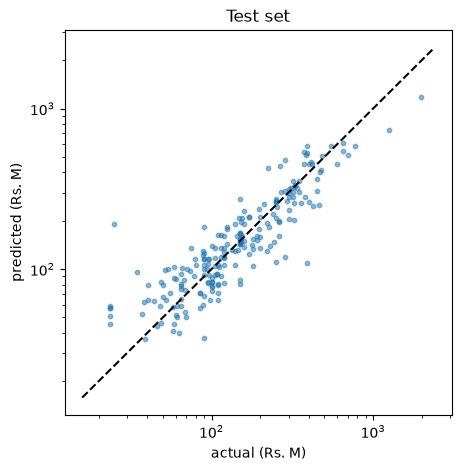

46% of test houses predicted within ±20% of asking price


In [21]:
lim = [y.min() * 0.8, y.max() * 1.2]
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, s=10, alpha=0.5)
plt.plot(lim, lim, "k--")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("actual (Rs. M)"); plt.ylabel("predicted (Rs. M)"); plt.title("Test set")
plt.show()

within = np.mean(np.abs(pred / y_test - 1) <= 0.2) * 100
print(f"{within:.0f}% of test houses predicted within ±20% of asking price")

In [22]:
check = df.loc[X_test.index, ["location", "sqft", "perches", "bedrooms", "price_m"]].copy()
check["predicted_m"] = pred.round(1)
check["error_%"] = ((check["predicted_m"] / check["price_m"] - 1) * 100).round(0)
check.sort_values("error_%", key=abs).iloc[::len(check) // 10]

,location,sqft,perches,bedrooms,price_m,predicted_m,error_%
1067,Battaramulla,3800.0,10.0,5.0,105.0,104.8,-0.0
328,Colombo 4,4500.0,19.0,6.0,302.0,315.3,4.0
39,Colombo 5,4700.0,13.0,9.0,250.0,266.9,7.0
371,Colombo 6,2000.0,5.6,4.0,105.0,92.5,-12.0
799,Delkanda,3200.0,17.0,4.0,78.0,90.4,16.0
312,Colombo 8,1950.0,5.75,4.0,100.0,77.6,-22.0
265,Colombo 5,7800.0,38.8,6.0,700.0,511.4,-27.0
445,Colombo 7,4000.0,23.0,5.0,385.0,514.4,34.0
1031,Battaramulla,1550.0,6.5,3.0,37.0,52.2,41.0
572,Dehiwala,4500.0,7.5,6.0,66.0,101.3,53.0


## 11. Save & Predict

In [23]:
import joblib

final = models["4 Log-log LR + area"].fit(X, y)   # refit on all clean data
joblib.dump(final, "sl_house_price_model.pkl")

def predict_price(sqft, perches, bedrooms, bathrooms, area):
    row = pd.DataFrame([dict(sqft=sqft, perches=perches, bedrooms=bedrooms, bathrooms=bathrooms, area=area)])
    return final.predict(row)[0]

for args in [(3000, 10, 4, 3, "Nugegoda"), (3000, 10, 4, 3, "Dehiwala"), (3000, 10, 4, 3, "Colombo 7")]:
    print(f"{args[-1]:<10} 3,000 sqft, 10 perches, 4BR/3BA -> Rs. {predict_price(*args):6.1f}M")

Nugegoda   3,000 sqft, 10 perches, 4BR/3BA -> Rs.   78.3M
Dehiwala   3,000 sqft, 10 perches, 4BR/3BA -> Rs.   88.9M
Colombo 7  3,000 sqft, 10 perches, 4BR/3BA -> Rs.  235.7M


## Summary

- Cleaning removed duplicates, non-priced ads and typos before any modelling.
- Log price + log size + location gives the best linear model; location is the strongest feature after size.
- Errors are multiplicative (~±30% typical), so report MAPE alongside MAE.
- Asking prices ≠ sale prices; the model learns what sellers ask.

**Next week:** overfitting, bias–variance and Ridge/Lasso in depth.